In [34]:
import numpy as np
import matplotlib.pyplot as plt
from src.functions_generator import FunctionsGenerator
from src.heat1D_crank_nicolson_solver import Heat1DCrankNicolson

plt.style.use("styles/plots.mplstyle")
np.random.seed(42)

In [35]:
def phi_theta(omega,a,b,c):
    return a*omega + b*omega**3 + c*omega**5

def R_theta(omega,a,b,c):
    return a + b*omega**2 + c*omega**4

def W_theta(G, phi, R):
    return np.conjugate(G)*np.exp(1j * phi) / (np.abs(G)**2 + R)

In [36]:
# Parametri simulazione
L = 1
Tf = 10
nt = 5000
D = 1
wanted_r = 0.5
h = 1
l = 1

In [37]:
# Inizializza solver
solver = Heat1DCrankNicolson(L,Tf,nt,D,h,wanted_r=wanted_r)

# Function generator
f_generator = FunctionsGenerator(solver.t_array, l=1)

In [38]:
n = solver.nt*2-1

impulse_response = solver.impulse_response()[-1]
IMPULSE_RESPONSE = np.fft.rfft(impulse_response, n) # Trasformata della risposta all'impulso

#f = np.sin(solver.t_array*2*np.pi/solver.Tf)
f = f_generator.generate_from_white_noise()
F = np.fft.rfft(f, n) # Trasformata del bordo 0

g = solver.solve_from_impulse_response(f, impulse_response)
G = np.fft.rfft(g, n) # Trasformata del bordo L

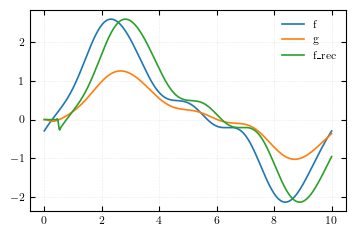

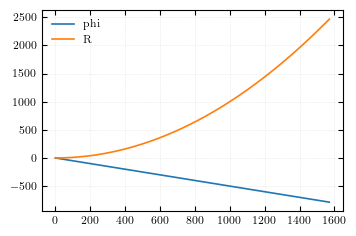

In [40]:
a_phi, b_phi, c_phi = -0.5, 0, 0
a_R, b_R, c_R = 0, 1e-3, 0

omegas = np.fft.rfftfreq(n, d=solver.dt) * 2 * np.pi

W = W_theta(IMPULSE_RESPONSE, phi = phi_theta(omegas,a_phi, b_phi, c_phi), R=R_theta(omegas,a_R, b_R, c_R))
F_RECONSTRUCTED = (W * G) / solver.dt
f_reconstructed = np.fft.irfft(F_RECONSTRUCTED,n)[:solver.nt]

# Plot ricostruzioni
plt.figure()
plt.plot(solver.t_array, f, label="f")
plt.plot(solver.t_array, g, label="g")
plt.plot(solver.t_array, f_reconstructed, label="f_rec")
plt.legend()
plt.grid()
plt.show()

# Plot funzioni phi, R
plt.figure()
plt.plot(omegas, phi_theta(omegas, a_phi, b_phi, c_phi), label="phi")
plt.plot(omegas, R_theta(omegas, a_R, b_R, c_R), label="R")
plt.legend()
plt.grid()
plt.show()